In [1]:
import matplotlib.pyplot as plt
import numpy as np
import h5py

from scipy import constants
from ipywidgets import interact
import matplotlib as mpl
mpl.rcParams['font.family'] = ['serif']
mpl.rcParams['font.serif'] = ['Times New Roman']
mpl.rcParams["mathtext.fontset"] = "cm"

######################### Physical constants #########################
Temperature         = 293                       # gas temperature, K
lambda0             = 0.81e-6                   # laser wavelength, m
c                   = constants.c               # lightspeed, m/s
omega0              = 2*np.pi*c/lambda0         # laser angular frequency, rad/s
eps0                = constants.epsilon_0       # Vacuum permittivity, F/m
e                   = constants.e               # Elementary charge, C
me                  = constants.m_e             # Electron mass, kg
kb                  = constants.Boltzmann       # Boltmann constant, J/K
hbar                = constants.hbar

######################### Laser Parameters #########################
I0     = 2.5 * 1e14                        # laser maximal peak intensity if propagating in vaccum (corresponding to 2.5 W/cm2)

######################### Gas Parameters  #########################
p_in_mbar = 20.
p         = p_in_mbar*1E2                       # pressure, Pa
n0        = p/kb/Temperature                    # gas density in m-3

######################### Cutoff Energy  #########################
Ipev     = 15.7596 #for Ar in eV
Upev     = 9.33*(I0*1E-14)*(lambda0*1E6)**2 #in eV
Ecutoof  = Ipev+3.17*Upev #in eV

#Some plot parameters
sizz=13
labelsizz=20
fontsizz=20
lww=3

In [2]:
orderN= np.arange(1,60,2,dtype=int)
order=[f'order_{No}' for No in orderN]
path_ref=''

with h5py.File(path_ref+'DiagRealField.h5', 'r') as h5:
    r = h5['r'][:]
    z = h5['z'][:]
    t = h5['t'][:]
    t=t-t[-1]/2.
    REq=np.zeros((len(order),len(t),len(z),len(r)),dtype=complex)
    REt=np.zeros((len(order),len(t),len(r)),dtype=complex)
    for j in range (len(t)):
        dataset_name = f"t_{j}"                                     
        for q in range (len(order)):
            REq[q,j,:,:] = h5[order[q]][dataset_name][:,:] 
        for q in range (len(order)):
            for qi in range (q,len(order)):
                REt[q,j,:]  += 1/2.*(REq[qi,j,-1,:]*np.exp(-1j*t[j]*omega0*orderN[qi])+np.conjugate(REq[qi,j,-1,:]*np.exp(-1j*t[j]*omega0*orderN[qi]))) #-1 to take the last position z


with h5py.File(path_ref+'DiagEnergy.h5', 'r') as h5:
    ze   = h5['z'][:]
    ceq = np.zeros((len(order),len(ze)))
    for q in range (len(order)):
        ceq[q,:]=h5[order[q]][:]


with h5py.File(path_ref+'DiagElectronDensity.h5', 'r') as h5:
    rn = h5['r'][:]
    zn = h5['z'][:]
    tn = h5['t'][:]
    tn=tn-tn[-1]/2.
    Ne=np.zeros((len(tn),len(zn),len(rn)))
    for j in range (len(tn)):
        dataset_name = f"t_{j}"
        Ne[j,:,:]=h5[dataset_name][:,:]

with h5py.File(path_ref+'DiagAtomicDensity.h5', 'r') as h5:
    rn = h5['r'][:]
    zn = h5['z'][:]
    tn = h5['t'][:]
    tn=tn-tn[-1]/2.
    Na=np.zeros((len(tn),len(zn),len(rn)))
    for j in range (len(tn)):
        dataset_name = f"t_{j}"
        Na[j,:,:]=h5[dataset_name][:,:]


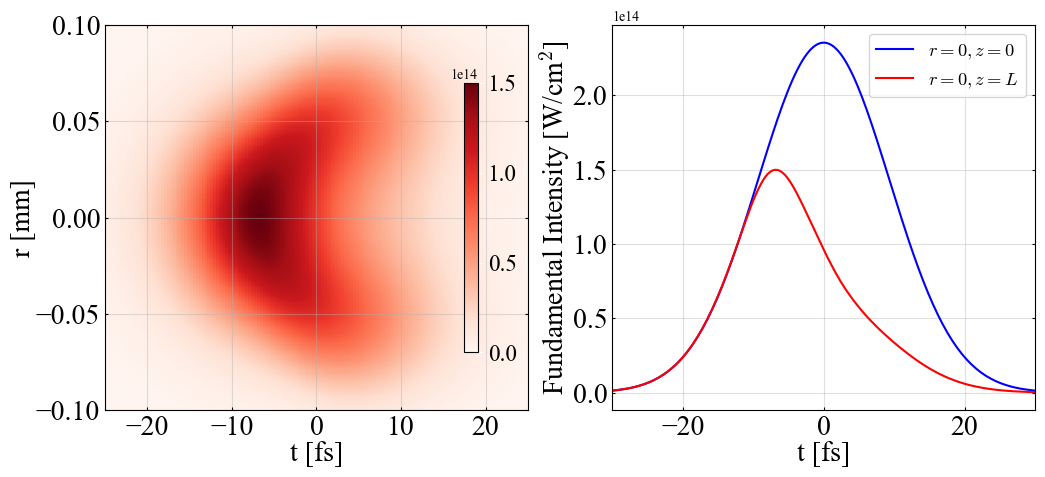

In [3]:
vmm0=1.5E14
xL=25

fig, axs = plt.subplots(1,2,figsize=(12,5))
ax=axs[0]
iq=0 #fundamental
img = ax.pcolormesh(t*1E15,r*1E3 ,(np.abs(REq[0,:,-1,:])**2*eps0*c/2.*1E-4).T,cmap='Reds',vmax=vmm0)
img = ax.pcolormesh(t*1E15,-r*1E3 ,(np.abs(REq[0,:,-1,:])**2*eps0*c/2.*1E-4).T,cmap='Reds',vmax=vmm0)

cbar = fig.colorbar(img,ax=ax,shrink=0.7,pad=-0.15)
cbar.set_label(r'Fundamental Intensity [W/cm$^2$]',fontsize=fontsizz, labelpad=15,color='black')
cbar.ax.tick_params(labelsize=fontsizz/1.2,color='white', labelcolor='black')


ax.set_ylim(-0.1,0.1)
ax.set_xlim(-xL,xL)
ax.set_xticks([-20,-10,0,10,20])
ax.set_yticks([-0.1,-0.05,0,0.05,0.1])
ax.grid(alpha=0.4)
ax.set_ylabel('r [mm]',fontsize=fontsizz,labelpad=0)
ax.set_xlabel('t [fs]',fontsize=fontsizz,labelpad=0)
ax.tick_params(labelsize=labelsizz)

ax.tick_params(
    axis='both',
    which='both',  
    #width=0.4,    
    length=2.0,    
    direction='in',
    top=True,
    right=True
)


ax=axs[1]
xL=30
iq=0 #fundamental
ax.plot(t*1E15,(np.abs(REq[0,:,0,0])**2*eps0*c/2.*1E-4),c='blue',label=r'$r=0,z=0$')
ax.plot(t*1E15,(np.abs(REq[0,:,-1,0])**2*eps0*c/2.*1E-4),c='red',label=r'$r=0,z=L$')


#ax.set_ylim(-0.1,0.1)
ax.set_xlim(-xL,xL)
#ax.set_xticks([-20,-10,0,10,20])

ax.grid(alpha=0.4)

ax.set_xlabel('t [fs]',fontsize=fontsizz,labelpad=0)
ax.tick_params(labelsize=labelsizz)

ax.tick_params(
    axis='both',
    which='both',  
    #width=0.4,    
    length=2.0,    
    direction='in',
    top=True,
    right=True
)

ax.legend(fontsize=fontsizz/1.5,loc='upper right')
#plt.savefig('doc/source/_static/fig_I1.png',format='png',transparent=True,bbox_inches="tight")
plt.show()


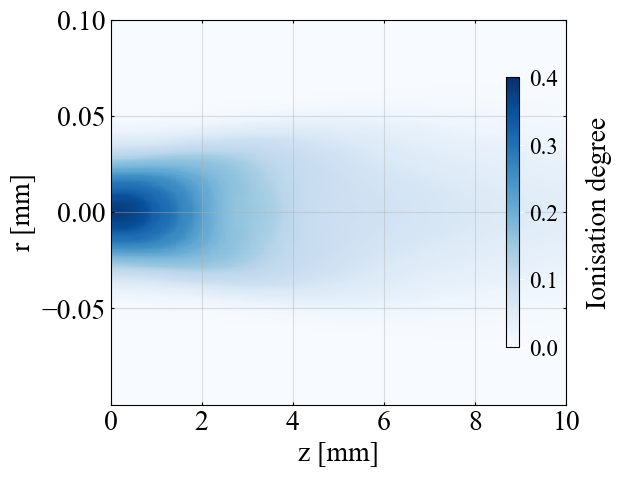

In [4]:
fig, axs = plt.subplots(1,1,figsize=(6,5))
ax=axs
img = ax.pcolormesh(zn*1E3,rn*1E3,(Ne[-1,:,:].T)/n0,cmap='Blues',vmax=0.4)


img = ax.pcolormesh(zn*1E3,-rn*1E3,(Ne[-1,:,:].T)/n0,cmap='Blues',vmax=.4)

cbar = fig.colorbar(img,ax=ax,shrink=0.7,pad=-0.13)
cbar.set_label('Ionisation degree',fontsize=fontsizz,color='black',labelpad=20)
cbar.ax.tick_params(labelsize=fontsizz/1.2,color='white', labelcolor='black')

ax.set_ylim(-0.1,0.1)
ax.set_xlim(0,10.)
ax.grid(alpha=0.4)
ax.set_ylabel('r [mm]',fontsize=fontsizz)
ax.set_xlabel('z [mm]',fontsize=fontsizz)
ax.tick_params(labelsize=labelsizz)

ax.set_yticks([-0.05,0,0.05,0.1])
ax.tick_params(
    axis='both',
    which='both',  
    #width=0.4,    
    length=2.0,    
    direction='in',
    top=True,
    right=True
)
#plt.savefig('doc/source/_static/fig_Ne.png',format='png',transparent=True,bbox_inches="tight")
plt.show()



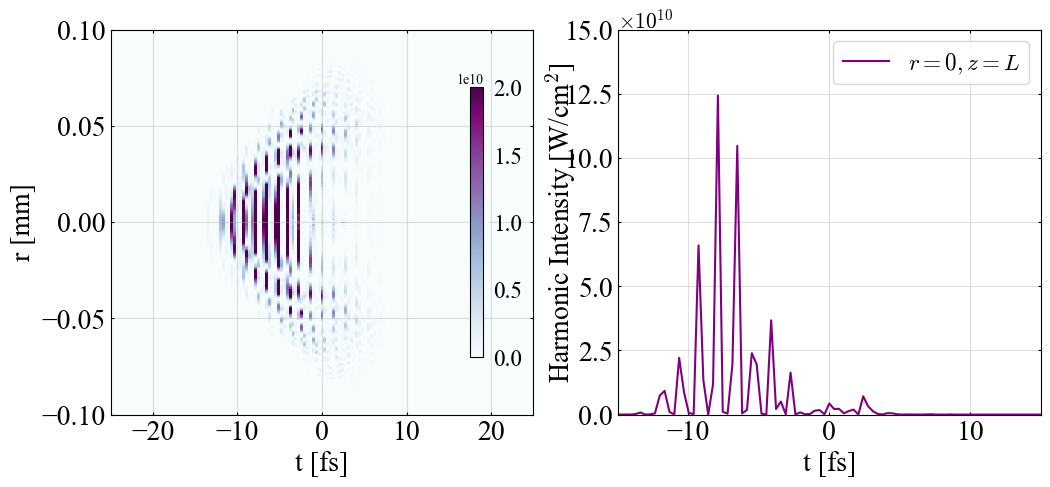

In [5]:

vmm1=2*1E10
xL=25
cmmm="BuPu"

fig, axs = plt.subplots(1,2,figsize=(12,5))
iq=11 #corresponding to harmonic larger than orderN[iq] (orderN[11]=23)
ax=axs[0]
img = ax.pcolormesh(t*1E15,r*1E3 ,(np.abs(REt[iq,:,:])**2*eps0*c*1E-4).T,cmap=cmmm,vmax=vmm1)
img = ax.pcolormesh(t*1E15,-r*1E3 ,(np.abs(REt[iq,:,:])**2*eps0*c*1E-4).T,cmap=cmmm,vmax=vmm1)

cbar = fig.colorbar(img,ax=ax,shrink=0.7,pad=-0.15)
cbar.set_label(r'Harmonic Intensity [W/cm$^2$]',fontsize=fontsizz,color='black',labelpad=15)
cbar.ax.tick_params(labelsize=fontsizz/1.2,color='white', labelcolor='black')

ax.set_ylim(-0.1,0.1)
ax.set_xlim(-xL,xL)
ax.set_xticks([-20,-10,0,10,20])
ax.grid(alpha=0.4)
ax.set_ylabel('r [mm]',fontsize=fontsizz)
ax.set_xlabel('t [fs]',fontsize=fontsizz)
ax.tick_params(labelsize=labelsizz)
ax.tick_params(
    axis='both',
    which='both',     
    length=2.0,    
    direction='in',
    top=True,
    right=True
)


ax=axs[1]
ir=0 #at r=0
iq=11 #corresponding to harmonic order orderN[iq] (here 23)

ax.plot(t*1E15,(np.abs(REt[iq,:,ir])**2*eps0*c*1E-4)*1E-10,'-',color='purple',label=r'$r=0, z=L$')
ax.text(-15,15.05,r'$\times 10^{10}$',fontsize=fontsizz/1.3)
ax.set_xlim(-15,15)

ax.set_ylim(0.,15.)
ax.grid(alpha=0.4)

#ax.set_ylabel(r'Harmonic Field Intensity [W/cm$^2$]',fontsize=fontsizz,labelpad=5)
ax.set_xlabel('t [fs]',fontsize=fontsizz)
ax.tick_params(labelsize=labelsizz)

ax.tick_params(
    axis='both',
    which='both',  
    #width=0.4,    
    length=2.0,    
    direction='in',
    top=True,
    right=True
)
ax.legend(fontsize=fontsizz/1.2,loc='upper right')

#plt.savefig('doc/source/_static/fig_Iq.png',format='png',transparent=True,bbox_inches="tight")
plt.show()


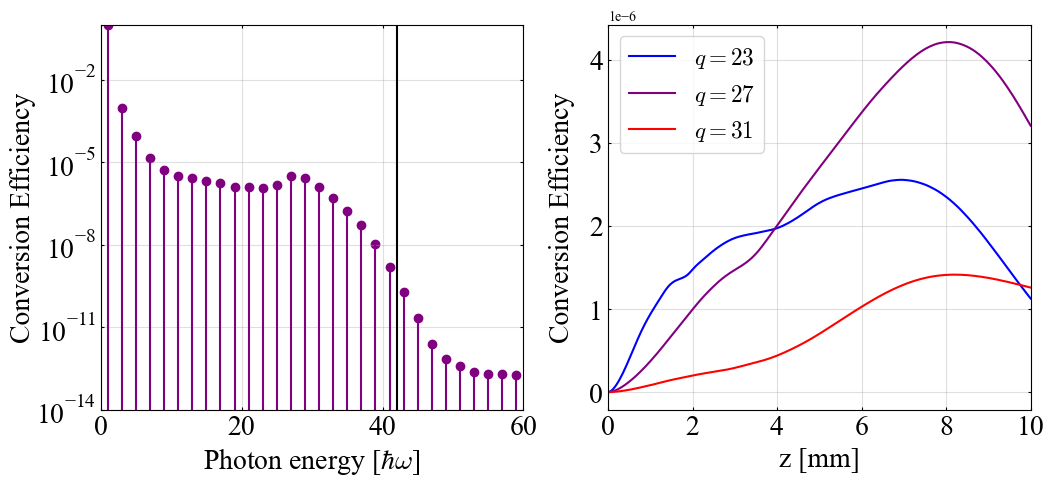

In [6]:
fig, axs = plt.subplots(1,2,figsize=(12,5))

ax=axs[0]
ax.grid(alpha=0.4)
ax.set_ylabel('Conversion Efficiency',fontsize=fontsizz,labelpad=0)
ax.set_xlabel(r'Photon energy [$\hbar \omega$]',fontsize=fontsizz)
ax.set_yscale('log')
ax.set_ylim(1e-14,1)
ax.set_xlim(0,60)

ax.tick_params(labelsize=labelsizz)

iz=-1 #end of the simulation box
ax.vlines(orderN,0,ceq[:,iz]/ceq[0,iz],color='purple')
ax.scatter(orderN,ceq[:,iz]/ceq[0,iz],label='HarP',color='purple')

ax.plot([Ecutoof/(hbar* omega0/e),Ecutoof/(hbar* omega0/e)],[1e-100,1],'-',c='black',label='Cutoff Energy')

ax.tick_params(
    axis='both',
    which='both',       
    #width=0.4,    
    length=2.0,    
    direction='in',
    top=True,
    right=True
)

ax=axs[1]
iq=11 #corresponding to harmonic order orderN[iq] (here 23)

ax.plot(ze*1E3,ceq[iq]/ceq[0],'-',color='blue',label=rf'$q={orderN[iq]}$')

iq=13 #corresponding to harmonic order orderN[iq] (here 27)
ax.plot(ze*1E3,ceq[iq]/ceq[0],'-',color='purple',label=rf'$q={orderN[iq]}$')
ax.set_xlim(0.,10.)

iq=15 #corresponding to harmonic order orderN[iq] (here 31)
ax.plot(ze*1E3,ceq[iq]/ceq[0],'-',color='red',label=rf'$q={orderN[iq]}$')
ax.set_xlim(0.,10.)


ax.grid(alpha=0.4)
ax.set_ylabel(f'Conversion Efficiency',fontsize=fontsizz,labelpad=10)
ax.set_xlabel('z [mm]',fontsize=fontsizz)
ax.tick_params(labelsize=labelsizz)


ax.tick_params(
    axis='both',
    which='both',  
    #width=0.4,    
    length=2.0,    
    direction='in',
    top=True,
    right=True
)

ax.legend(fontsize=fontsizz/1.2,loc='upper left')

#plt.savefig('doc/source/_static/fig_CE.png',format='png',transparent=True,bbox_inches="tight")
plt.show()